In [1]:
# STEP 25: IMPORTED FORECASTING DATASET

import pandas as pd
from pathlib import Path

# Location of our processed AirPods dataset
file_path = Path("data/processed/airpods_weekly_2019.csv")

# Import the CSV and convert dates automatically
df_forecast = pd.read_csv(
    file_path,
    parse_dates=["Week_Ending"]
)

# Display dataset information
print("===== FORECASTING DATASET =====")
print("Total weeks:", len(df_forecast))
print("Columns:", df_forecast.columns.tolist())

# Check data types
print("\nData types:")
print(df_forecast.dtypes)

# Validate missing values
print("\nMissing values:")
print(df_forecast.isna().sum())

# Check that all weeks are exactly 7 days apart
print("\nNon-weekly gaps:")
print(
    (
        df_forecast["Week_Ending"]
        .diff()
        .dropna()
        != pd.Timedelta(days=7)
    ).sum()
)

# Preview the data
print("\nFirst five weeks:")
display(df_forecast.head())

print("\nLast five weeks:")
display(df_forecast.tail())


===== FORECASTING DATASET =====
Total weeks: 51
Columns: ['Week_Ending', 'Units_Sold']

Data types:
Week_Ending    datetime64[us]
Units_Sold              int64
dtype: object

Missing values:
Week_Ending    0
Units_Sold     0
dtype: int64

Non-weekly gaps:
0

First five weeks:


,Week_Ending,Units_Sold
0,2019-01-13,187
1,2019-01-20,184
2,2019-01-27,175
3,2019-02-03,225
4,2019-02-10,247



Last five weeks:


,Week_Ending,Units_Sold
46,2019-12-01,356
47,2019-12-08,450
48,2019-12-15,481
49,2019-12-22,456
50,2019-12-29,515


In [2]:
# STEP 26: ANALYZE AIRPODS DEMAND VARIABILITY

# Calculate basic weekly demand statistics
average_demand = df_forecast["Units_Sold"].mean()
median_demand = df_forecast["Units_Sold"].median()
minimum_demand = df_forecast["Units_Sold"].min()
maximum_demand = df_forecast["Units_Sold"].max()
std_demand = df_forecast["Units_Sold"].std()

# Calculate coefficient of variation (CV)
cv = (std_demand / average_demand) * 100

# Display results
print("===== WEEKLY DEMAND STATISTICS =====")
print(f"Average weekly demand: {average_demand:.1f}")
print(f"Median weekly demand: {median_demand:.1f}")
print(f"Minimum weekly demand: {minimum_demand}")
print(f"Maximum weekly demand: {maximum_demand}")
print(f"Standard deviation: {std_demand:.1f}")
print(f"Coefficient of variation: {cv:.1f}%")

# Identify the five highest-demand weeks
print("\n===== TOP 5 DEMAND WEEKS =====")
display(
    df_forecast.nlargest(5, "Units_Sold")
)

# Identify the five lowest-demand weeks
print("\n===== BOTTOM 5 DEMAND WEEKS =====")
display(
    df_forecast.nsmallest(5, "Units_Sold")
)

===== WEEKLY DEMAND STATISTICS =====
Average weekly demand: 301.3
Median weekly demand: 285.0
Minimum weekly demand: 175
Maximum weekly demand: 515
Standard deviation: 76.5
Coefficient of variation: 25.4%

===== TOP 5 DEMAND WEEKS =====


,Week_Ending,Units_Sold
50,2019-12-29,515
48,2019-12-15,481
49,2019-12-22,456
47,2019-12-08,450
15,2019-04-28,398



===== BOTTOM 5 DEMAND WEEKS =====


,Week_Ending,Units_Sold
2,2019-01-27,175
1,2019-01-20,184
0,2019-01-13,187
36,2019-09-22,210
30,2019-08-11,224


In [3]:
# STEP 27: CREATE TRAINING AND TESTING DATASETS

# Sort historical demand in chronological order
df_forecast = df_forecast.sort_values(
    "Week_Ending"
).reset_index(drop=True)

# Reserve the final 12 weeks for testing
test_weeks = 12

# Create training dataset (earlier weeks)
train = df_forecast.iloc[:-test_weeks].copy()

# Create testing dataset (final 12 weeks)
test = df_forecast.iloc[-test_weeks:].copy()

# Display results
print("===== TRAIN / TEST SPLIT =====")

print("Total observations:", len(df_forecast))
print("Training weeks:", len(train))
print("Testing weeks:", len(test))

print("\nTraining period:")
print(train["Week_Ending"].min(), "to",
      train["Week_Ending"].max())

print("\nTesting period:")
print(test["Week_Ending"].min(), "to",
      test["Week_Ending"].max())

# Check that the periods do not overlap
print("\nChronological split valid:",
      train["Week_Ending"].max() <
      test["Week_Ending"].min())

# Preview training and testing datasets
print("\nLast 5 training observations:")
display(train.tail())

print("\nFirst 5 testing observations:")
display(test.head())


===== TRAIN / TEST SPLIT =====
Total observations: 51
Training weeks: 39
Testing weeks: 12

Training period:
2019-01-13 00:00:00 to 2019-10-06 00:00:00

Testing period:
2019-10-13 00:00:00 to 2019-12-29 00:00:00

Chronological split valid: True

Last 5 training observations:


,Week_Ending,Units_Sold
34,2019-09-08,231
35,2019-09-15,235
36,2019-09-22,210
37,2019-09-29,229
38,2019-10-06,377



First 5 testing observations:


,Week_Ending,Units_Sold
39,2019-10-13,370
40,2019-10-20,364
41,2019-10-27,372
42,2019-11-03,379
43,2019-11-10,341


In [4]:
# STEP 28: BUILD NAIVE BASELINE FORECAST

# Identify the last observed sales value in training data
last_train_demand = train["Units_Sold"].iloc[-1]

# Create a copy of the testing dataset
naive_results = test.copy()

# Predict the same demand for every future test week
naive_results["Naive_Forecast"] = last_train_demand

# Display forecast information
print("===== NAIVE BASELINE FORECAST =====")

print("Last observed training demand:",
      last_train_demand)

print("Number of forecasted weeks:",
      len(naive_results))

print("\n===== ACTUAL VS FORECASTED DEMAND =====")

display(
    naive_results[
        ["Week_Ending", "Units_Sold", "Naive_Forecast"]
    ]
)


===== NAIVE BASELINE FORECAST =====
Last observed training demand: 377
Number of forecasted weeks: 12

===== ACTUAL VS FORECASTED DEMAND =====


,Week_Ending,Units_Sold,Naive_Forecast
39,2019-10-13,370,377
40,2019-10-20,364,377
41,2019-10-27,372,377
42,2019-11-03,379,377
43,2019-11-10,341,377
44,2019-11-17,354,377
45,2019-11-24,345,377
46,2019-12-01,356,377
47,2019-12-08,450,377
48,2019-12-15,481,377


In [5]:
# STEP 29: EVALUATE NAIVE FORECAST ACCURACY

# Calculate the forecasting error for each week
# Positive error means we overforecasted demand
naive_results["Forecast_Error"] = (
    naive_results["Naive_Forecast"] -
    naive_results["Units_Sold"]
)

# Calculate absolute errors
naive_results["Absolute_Error"] = (
    naive_results["Forecast_Error"].abs()
)

# Calculate Mean Absolute Error (MAE)
mae = naive_results["Absolute_Error"].mean()

# Calculate Weighted Absolute Percentage Error (WAPE)
wape = (
    naive_results["Absolute_Error"].sum() /
    naive_results["Units_Sold"].sum()
) * 100

# Calculate Forecast Bias
bias = naive_results["Forecast_Error"].mean()

# Display evaluation results
print("===== NAIVE FORECAST ACCURACY =====")

print(f"Mean Absolute Error (MAE): {mae:.2f} units")
print(f"WAPE: {wape:.2f}%")
print(f"Forecast Bias: {bias:.2f} units")

# Interpret the direction of bias
if bias > 0:
    print("Interpretation: Model overforecasts demand.")
elif bias < 0:
    print("Interpretation: Model underforecasts demand.")
else:
    print("Interpretation: No net forecast bias.")

print("\n===== WEEKLY FORECAST ERRORS =====")

display(
    naive_results[
        [
            "Week_Ending",
            "Units_Sold",
            "Naive_Forecast",
            "Forecast_Error",
            "Absolute_Error"
        ]
    ]
)


===== NAIVE FORECAST ACCURACY =====
Mean Absolute Error (MAE): 44.42 units
WAPE: 11.14%
Forecast Bias: -21.58 units
Interpretation: Model underforecasts demand.

===== WEEKLY FORECAST ERRORS =====


,Week_Ending,Units_Sold,Naive_Forecast,Forecast_Error,Absolute_Error
39,2019-10-13,370,377,7,7
40,2019-10-20,364,377,13,13
41,2019-10-27,372,377,5,5
42,2019-11-03,379,377,-2,2
43,2019-11-10,341,377,36,36
44,2019-11-17,354,377,23,23
45,2019-11-24,345,377,32,32
46,2019-12-01,356,377,21,21
47,2019-12-08,450,377,-73,73
48,2019-12-15,481,377,-104,104


In [6]:
# STEP 30: BUILD FOUR-WEEK MOVING AVERAGE FORECAST

# Select the last four weeks of training data
last_four_weeks = train["Units_Sold"].tail(4)

# Calculate their average demand
ma4_forecast = last_four_weeks.mean()

# Create a new testing dataset
ma4_results = test.copy()

# Apply the same forecast to all 12 testing weeks
ma4_results["MA4_Forecast"] = ma4_forecast

# Display our model information
print("===== FOUR-WEEK MOVING AVERAGE FORECAST =====")

print("\nLast four training observations:")
display(train.tail(4))

print(
    "\nAverage demand from last four weeks:",
    round(ma4_forecast, 2)
)

print(
    "\nNumber of forecasted weeks:",
    len(ma4_results)
)

# Display predicted demand against actual demand
print("\n===== ACTUAL VS MOVING AVERAGE FORECAST =====")

display(
    ma4_results[
        ["Week_Ending", "Units_Sold", "MA4_Forecast"]
    ]
)


===== FOUR-WEEK MOVING AVERAGE FORECAST =====

Last four training observations:


,Week_Ending,Units_Sold
35,2019-09-15,235
36,2019-09-22,210
37,2019-09-29,229
38,2019-10-06,377



Average demand from last four weeks: 262.75

Number of forecasted weeks: 12

===== ACTUAL VS MOVING AVERAGE FORECAST =====


,Week_Ending,Units_Sold,MA4_Forecast
39,2019-10-13,370,262.75
40,2019-10-20,364,262.75
41,2019-10-27,372,262.75
42,2019-11-03,379,262.75
43,2019-11-10,341,262.75
44,2019-11-17,354,262.75
45,2019-11-24,345,262.75
46,2019-12-01,356,262.75
47,2019-12-08,450,262.75
48,2019-12-15,481,262.75


In [7]:
# STEP 31: EVALUATE MOVING AVERAGE FORECAST

# Calculate forecast errors
# Positive = overforecast, negative = underforecast
ma4_results["Forecast_Error"] = (
    ma4_results["MA4_Forecast"] -
    ma4_results["Units_Sold"]
)

# Calculate absolute errors
ma4_results["Absolute_Error"] = (
    ma4_results["Forecast_Error"].abs()
)

# Calculate Mean Absolute Error
ma4_mae = ma4_results["Absolute_Error"].mean()

# Calculate Weighted Absolute Percentage Error
ma4_wape = (
    ma4_results["Absolute_Error"].sum() /
    ma4_results["Units_Sold"].sum()
) * 100

# Calculate forecast bias
ma4_bias = ma4_results["Forecast_Error"].mean()

# Display results
print("===== MOVING AVERAGE FORECAST ACCURACY =====")

print(f"MAE: {ma4_mae:.2f} units")
print(f"WAPE: {ma4_wape:.2f}%")
print(f"Forecast Bias: {ma4_bias:.2f} units")

# Compare against our naive baseline
print("\n===== MODEL COMPARISON =====")

comparison = pd.DataFrame({
    "Model": [
        "Naive Forecast",
        "4-Week Moving Average"
    ],
    "MAE": [mae, ma4_mae],
    "WAPE (%)": [wape, ma4_wape],
    "Bias": [bias, ma4_bias]
})

display(comparison.round(2))

# Display weekly errors
print("\n===== WEEKLY MOVING AVERAGE ERRORS =====")

display(
    ma4_results[
        [
            "Week_Ending",
            "Units_Sold",
            "MA4_Forecast",
            "Forecast_Error",
            "Absolute_Error"
        ]
    ]
)


===== MOVING AVERAGE FORECAST ACCURACY =====
MAE: 135.83 units
WAPE: 34.08%
Forecast Bias: -135.83 units

===== MODEL COMPARISON =====


,Model,MAE,WAPE (%),Bias
0,Naive Forecast,44.42,11.14,-21.58
1,4-Week Moving Average,135.83,34.08,-135.83



===== WEEKLY MOVING AVERAGE ERRORS =====


,Week_Ending,Units_Sold,MA4_Forecast,Forecast_Error,Absolute_Error
39,2019-10-13,370,262.75,-107.25,107.25
40,2019-10-20,364,262.75,-101.25,101.25
41,2019-10-27,372,262.75,-109.25,109.25
42,2019-11-03,379,262.75,-116.25,116.25
43,2019-11-10,341,262.75,-78.25,78.25
44,2019-11-17,354,262.75,-91.25,91.25
45,2019-11-24,345,262.75,-82.25,82.25
46,2019-12-01,356,262.75,-93.25,93.25
47,2019-12-08,450,262.75,-187.25,187.25
48,2019-12-15,481,262.75,-218.25,218.25


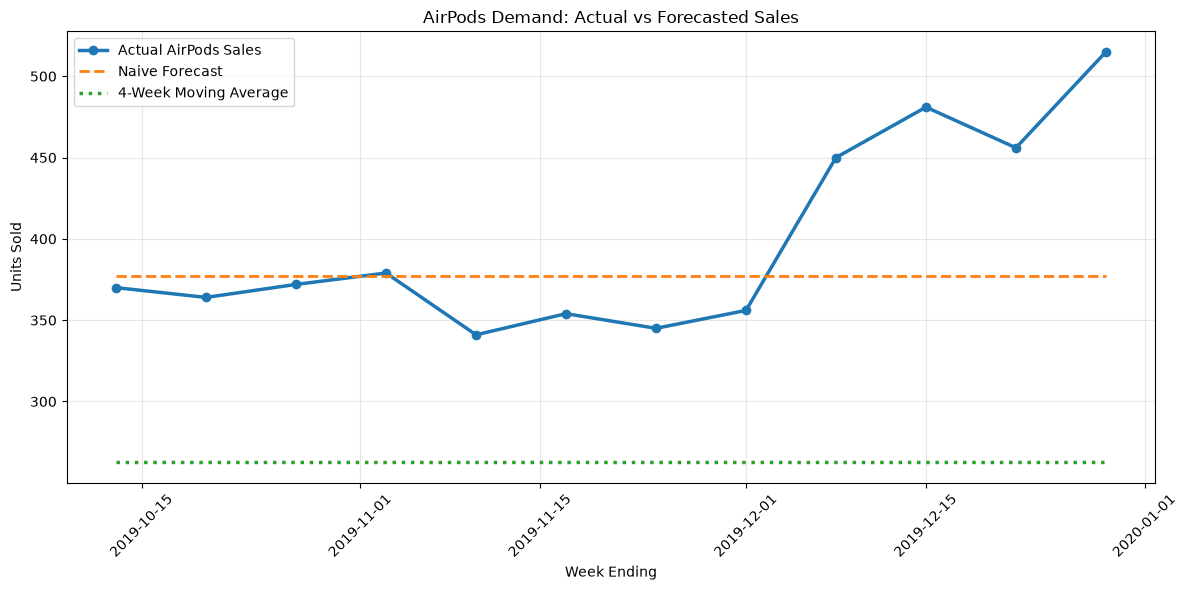

In [8]:
# STEP 32: VISUALIZE FORECAST MODEL COMPARISON

import matplotlib.pyplot as plt

# Create the figure
plt.figure(figsize=(12, 6))

# Plot actual weekly demand
plt.plot(
    test["Week_Ending"],
    test["Units_Sold"],
    marker="o",
    linewidth=2.5,
    label="Actual AirPods Sales"
)

# Plot naive baseline predictions
plt.plot(
    naive_results["Week_Ending"],
    naive_results["Naive_Forecast"],
    linestyle="--",
    linewidth=2,
    label="Naive Forecast"
)

# Plot moving average predictions
plt.plot(
    ma4_results["Week_Ending"],
    ma4_results["MA4_Forecast"],
    linestyle=":",
    linewidth=2.5,
    label="4-Week Moving Average"
)

# Format the chart
plt.title(
    "AirPods Demand: Actual vs Forecasted Sales"
)
plt.xlabel("Week Ending")
plt.ylabel("Units Sold")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# Display chart
plt.show()


In [9]:
# STEP 33: BUILD HOLT'S DAMPED-TREND FORECAST

from statsmodels.tsa.holtwinters import Holt
import numpy as np

# Prepare training data
train_values = train["Units_Sold"].to_numpy(dtype=float)

# Create a trend-aware forecasting model
holt_model = Holt(
    train_values,
    exponential=False,
    damped_trend=True,
    initialization_method="estimated"
)

# Train the model using historical observations
holt_fit = holt_model.fit(optimized=True)

# Forecast the next 12 weeks
holt_predictions = holt_fit.forecast(len(test))

# Create a results table
holt_results = test.copy()

holt_results["Holt_Forecast"] = np.asarray(
    holt_predictions,
    dtype=float
)

# Display results
print("===== HOLT'S DAMPED-TREND FORECAST =====")

print("Training weeks:", len(train))
print("Forecast horizon:", len(test))

print("\n===== ACTUAL VS PREDICTED DEMAND =====")

display(
    holt_results[
        ["Week_Ending", "Units_Sold", "Holt_Forecast"]
    ].round(2)
)


===== HOLT'S DAMPED-TREND FORECAST =====
Training weeks: 39
Forecast horizon: 12

===== ACTUAL VS PREDICTED DEMAND =====


/var/folders/9c/495l1cs96zj_67bnbpkg5lm80000gn/T/ipykernel_66175/3557115978.py:42: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Week_Ending,Units_Sold,Holt_Forecast
39,2019-10-13,370,293.11
40,2019-10-20,364,293.15
41,2019-10-27,372,293.18
42,2019-11-03,379,293.21
43,2019-11-10,341,293.23
44,2019-11-17,354,293.25
45,2019-11-24,345,293.27
46,2019-12-01,356,293.29
47,2019-12-08,450,293.30
48,2019-12-15,481,293.31


In [10]:
# STEP 34: EVALUATE HOLT'S FORECASTING MODEL

# Calculate forecast errors
# Positive = overforecast, negative = underforecast
holt_results["Forecast_Error"] = (
    holt_results["Holt_Forecast"]
    - holt_results["Units_Sold"]
)

# Calculate absolute forecast errors
holt_results["Absolute_Error"] = (
    holt_results["Forecast_Error"].abs()
)

# Calculate Mean Absolute Error
holt_mae = holt_results["Absolute_Error"].mean()

# Calculate Weighted Absolute Percentage Error
holt_wape = (
    holt_results["Absolute_Error"].sum()
    / holt_results["Units_Sold"].sum()
) * 100

# Calculate forecast bias
holt_bias = holt_results["Forecast_Error"].mean()

# Display Holt's performance
print("===== HOLT'S FORECAST ACCURACY =====")

print(f"MAE: {holt_mae:.2f} units")
print(f"WAPE: {holt_wape:.2f}%")
print(f"Forecast Bias: {holt_bias:.2f} units")

# Compare all three forecasting models
model_comparison = pd.DataFrame({
    "Model": [
        "Naive Forecast",
        "4-Week Moving Average",
        "Holt's Damped Trend"
    ],
    "MAE": [
        mae,
        ma4_mae,
        holt_mae
    ],
    "WAPE (%)": [
        wape,
        ma4_wape,
        holt_wape
    ],
    "Bias": [
        bias,
        ma4_bias,
        holt_bias
    ]
})

# Rank models by lowest forecasting error
model_comparison = model_comparison.sort_values(
    "MAE", ascending=True
).reset_index(drop=True)

print("\n===== THREE-MODEL COMPARISON =====")
display(model_comparison.round(2))

# Display weekly errors for Holt's model
print("\n===== HOLT'S WEEKLY ERRORS =====")

display(
    holt_results[
        [
            "Week_Ending",
            "Units_Sold",
            "Holt_Forecast",
            "Forecast_Error",
            "Absolute_Error"
        ]
    ].round({
        "Holt_Forecast": 2,
        "Forecast_Error": 2,
        "Absolute_Error": 2
    })
)


===== HOLT'S FORECAST ACCURACY =====
MAE: 105.34 units
WAPE: 26.43%
Forecast Bias: -105.34 units

===== THREE-MODEL COMPARISON =====


,Model,MAE,WAPE (%),Bias
0,Naive Forecast,44.42,11.14,-21.58
1,Holt's Damped Trend,105.34,26.43,-105.34
2,4-Week Moving Average,135.83,34.08,-135.83



===== HOLT'S WEEKLY ERRORS =====


,Week_Ending,Units_Sold,Holt_Forecast,Forecast_Error,Absolute_Error
39,2019-10-13,370,293.11,-76.89,76.89
40,2019-10-20,364,293.15,-70.85,70.85
41,2019-10-27,372,293.18,-78.82,78.82
42,2019-11-03,379,293.21,-85.79,85.79
43,2019-11-10,341,293.23,-47.77,47.77
44,2019-11-17,354,293.25,-60.75,60.75
45,2019-11-24,345,293.27,-51.73,51.73
46,2019-12-01,356,293.29,-62.71,62.71
47,2019-12-08,450,293.30,-156.70,156.70
48,2019-12-15,481,293.31,-187.69,187.69


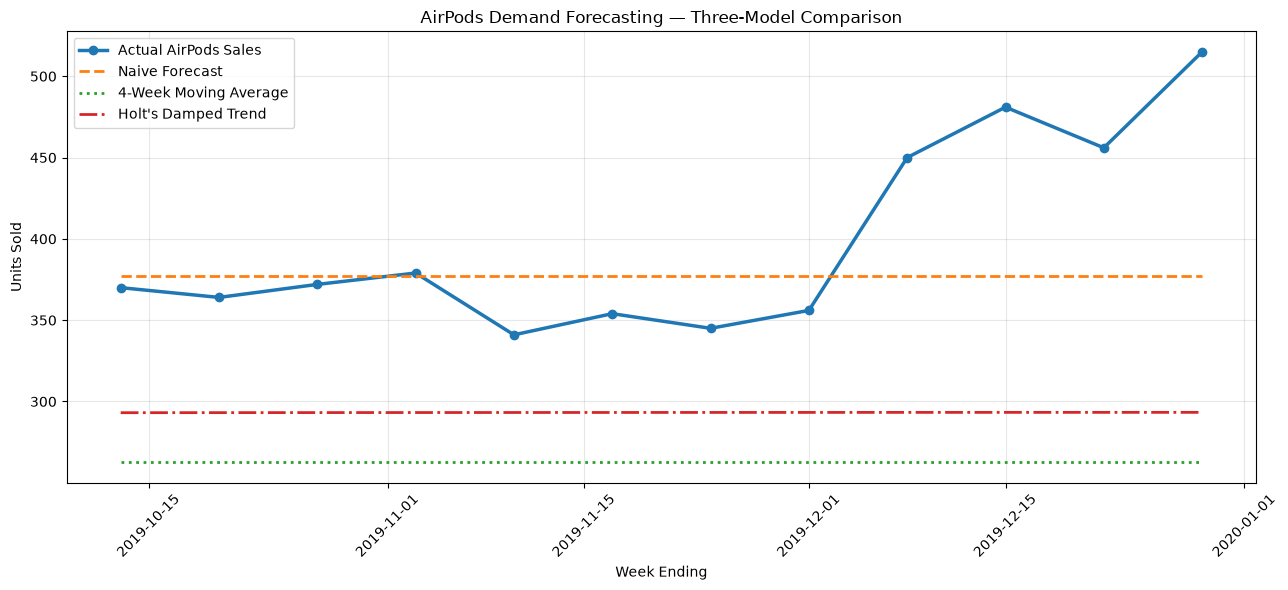

In [11]:
# STEP 35: VISUALIZE ALL THREE FORECASTING MODELS

import matplotlib.pyplot as plt

# Create visualization
plt.figure(figsize=(13, 6))

# Actual weekly sales
plt.plot(
    test["Week_Ending"],
    test["Units_Sold"],
    marker="o",
    linewidth=2.5,
    label="Actual AirPods Sales"
)

# Naive forecast
plt.plot(
    naive_results["Week_Ending"],
    naive_results["Naive_Forecast"],
    linestyle="--",
    linewidth=2,
    label="Naive Forecast"
)

# Four-week moving average
plt.plot(
    ma4_results["Week_Ending"],
    ma4_results["MA4_Forecast"],
    linestyle=":",
    linewidth=2,
    label="4-Week Moving Average"
)

# Holt's damped-trend forecast
plt.plot(
    holt_results["Week_Ending"],
    holt_results["Holt_Forecast"],
    linestyle="-.",
    linewidth=2,
    label="Holt's Damped Trend"
)

# Add chart titles and formatting
plt.title(
    "AirPods Demand Forecasting — Three-Model Comparison"
)
plt.xlabel("Week Ending")
plt.ylabel("Units Sold")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [12]:
# STEP 36: ROLLING-ORIGIN BACKTESTING

import pandas as pd

# Begin after the first 20 training weeks
initial_weeks = 20

# Store individual forecast results
backtest_records = []

# Move forward one week at a time
for i in range(initial_weeks, len(train)):

    # Historical observations available at this point
    history = train.iloc[:i]

    # Actual sales in the next week
    actual = train.iloc[i]["Units_Sold"]

    # Model 1: Naive forecast
    naive_prediction = history["Units_Sold"].iloc[-1]

    # Model 2: Four-week moving average
    ma4_prediction = history["Units_Sold"].tail(4).mean()

    # Store the predictions and actual sales
    backtest_records.append({
        "Week_Ending": train.iloc[i]["Week_Ending"],
        "Actual_Units": actual,
        "Naive_Forecast": naive_prediction,
        "MA4_Forecast": ma4_prediction
    })

# Combine all forecast records
backtest_results = pd.DataFrame(backtest_records)

print("===== ROLLING BACKTEST RESULTS =====")
print("Forecasts generated:", len(backtest_results))
print("Forecast horizon: 1 week")

display(backtest_results)

# Evaluate both models across all backtest weeks
metrics = []

for model in ["Naive_Forecast", "MA4_Forecast"]:

    errors = (
        backtest_results[model]
        - backtest_results["Actual_Units"]
    )

    metrics.append({
        "Model": model,
        "MAE": errors.abs().mean(),
        "WAPE (%)": (
            errors.abs().sum()
            / backtest_results["Actual_Units"].sum()
        ) * 100,
        "Bias": errors.mean()
    })

backtest_summary = pd.DataFrame(metrics)

print("\n===== BACKTEST MODEL COMPARISON =====")
display(backtest_summary.round(2))


===== ROLLING BACKTEST RESULTS =====
Forecasts generated: 19
Forecast horizon: 1 week


,Week_Ending,Actual_Units,Naive_Forecast,MA4_Forecast
0,2019-06-02,263,312,316.50
1,2019-06-09,267,263,302.75
2,2019-06-16,275,267,298.25
3,2019-06-23,265,275,279.25
4,2019-06-30,283,265,267.50
5,2019-07-07,284,283,272.50
6,2019-07-14,295,284,276.75
7,2019-07-21,262,295,281.75
8,2019-07-28,267,262,281.00
9,2019-08-04,227,267,277.00



===== BACKTEST MODEL COMPARISON =====


,Model,MAE,WAPE (%),Bias
0,Naive_Forecast,22.16,8.60,-3.42
1,MA4_Forecast,26.57,10.31,4.46


In [13]:
# STEP 37: ROLLING-ORIGIN BACKTEST FOR HOLT'S MODEL

from statsmodels.tsa.holtwinters import Holt
import numpy as np

# Store Holt's weekly predictions
holt_backtest_predictions = []

# Repeat forecasts using expanding historical windows
for i in range(initial_weeks, len(train)):

    # Use only information available before this week
    history = train["Units_Sold"].iloc[:i].to_numpy(
        dtype=float
    )

    # Build and train Holt's model
    model = Holt(
        history,
        exponential=False,
        damped_trend=True,
        initialization_method="estimated"
    )

    fitted_model = model.fit(optimized=True)

    # Forecast exactly one week ahead
    prediction = float(fitted_model.forecast(1)[0])

    holt_backtest_predictions.append(prediction)

# Add Holt predictions to our existing backtest table
backtest_results["Holt_Forecast"] = (
    holt_backtest_predictions
)

# Compare all three models over identical weeks
model_columns = [
    "Naive_Forecast",
    "MA4_Forecast",
    "Holt_Forecast"
]

results = []

for model_name in model_columns:

    errors = (
        backtest_results[model_name]
        - backtest_results["Actual_Units"]
    )

    results.append({
        "Model": model_name,
        "MAE": errors.abs().mean(),
        "WAPE (%)": (
            errors.abs().sum()
            / backtest_results["Actual_Units"].sum()
        ) * 100,
        "Bias": errors.mean()
    })

# Create ranked model comparison
rolling_comparison = pd.DataFrame(results)

rolling_comparison = rolling_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

print("===== THREE-MODEL ROLLING BACKTEST =====")

display(rolling_comparison.round(2))

print("\n===== HOLT'S ROLLING PREDICTIONS =====")

display(
    backtest_results[
        [
            "Week_Ending",
            "Actual_Units",
            "Holt_Forecast"
        ]
    ].round({"Holt_Forecast": 2})
)


===== THREE-MODEL ROLLING BACKTEST =====


,Model,MAE,WAPE (%),Bias
0,Naive_Forecast,22.16,8.60,-3.42
1,MA4_Forecast,26.57,10.31,4.46
2,Holt_Forecast,28.24,10.96,1.10



===== HOLT'S ROLLING PREDICTIONS =====


,Week_Ending,Actual_Units,Holt_Forecast
0,2019-06-02,263,343.71
1,2019-06-09,267,331.21
2,2019-06-16,275,270.87
3,2019-06-23,265,262.93
4,2019-06-30,283,255.18
5,2019-07-07,284,261.47
6,2019-07-14,295,281.85
7,2019-07-21,262,287.64
8,2019-07-28,267,277.52
9,2019-08-04,227,273.40


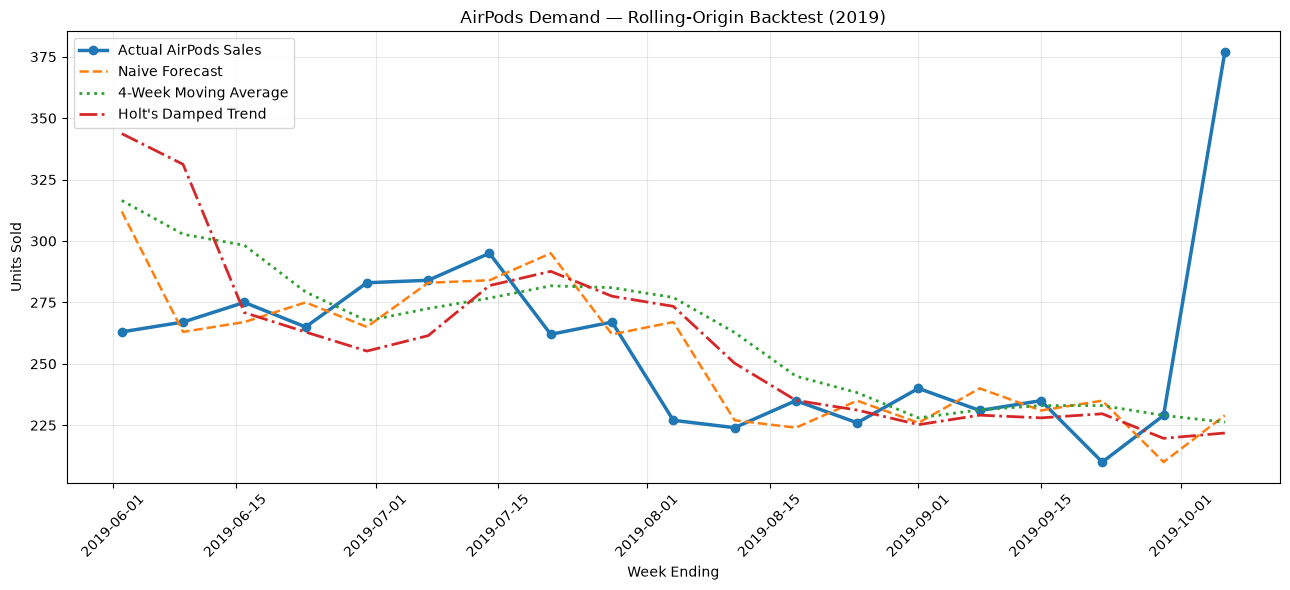

In [14]:
# STEP 38: VISUALIZE ROLLING BACKTEST PERFORMANCE

import matplotlib.pyplot as plt

# Create the chart
plt.figure(figsize=(13, 6))

# Actual demand
plt.plot(
    backtest_results["Week_Ending"],
    backtest_results["Actual_Units"],
    marker="o",
    linewidth=2.5,
    label="Actual AirPods Sales"
)

# Naive forecast
plt.plot(
    backtest_results["Week_Ending"],
    backtest_results["Naive_Forecast"],
    linestyle="--",
    linewidth=1.8,
    label="Naive Forecast"
)

# Four-week moving average
plt.plot(
    backtest_results["Week_Ending"],
    backtest_results["MA4_Forecast"],
    linestyle=":",
    linewidth=2,
    label="4-Week Moving Average"
)

# Holt's damped trend
plt.plot(
    backtest_results["Week_Ending"],
    backtest_results["Holt_Forecast"],
    linestyle="-.",
    linewidth=2,
    label="Holt's Damped Trend"
)

# Format the visualization
plt.title(
    "AirPods Demand — Rolling-Origin Backtest (2019)"
)

plt.xlabel("Week Ending")
plt.ylabel("Units Sold")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()



## Baseline Forecasting — Findings & Methodology

### Business Objective
Evaluate whether historical weekly sales can generate
reliable short-term demand forecasts for wireless earbuds.

### Dataset
- Product: Apple Airpods Headphones
- Historical period: January–December 2019
- Weekly observations: 51 complete weeks
- Average weekly sales: 301.3 units
- Coefficient of variation: 25.4%

### Forecasting Models
1. Naive Last-Value Forecast
2. Four-Week Moving Average
3. Holt's Damped-Trend Exponential Smoothing

### Evaluation Method 1 — Fixed-Origin Forecast
- Training: 39 weeks
- Testing: 12 weeks
- Forecast horizon: 12 weeks
- Forecasts generated without using test-period observations

Results:
- Naive MAE: 44.42
- Moving Average MAE: 135.83
- Holt's MAE: 105.34

### Evaluation Method 2 — Rolling-Origin Backtesting
- Initial training window: 20 weeks
- Evaluation period: June–October 2019
- Forecast horizon: 1 week
- Historical forecast simulations: 19
- Training window expands after each observed week

Results:
- Naive: MAE 22.16, WAPE 8.60%
- Moving Average: MAE 26.57, WAPE 10.31%
- Holt's: MAE 28.24, WAPE 10.96%

### Key Findings
1. Naive forecasting achieved the lowest MAE in both
   evaluation approaches.
2. Holt's model showed the lowest bias during rolling
   backtesting but had higher absolute errors.
3. All three models substantially underestimated the
   sales increase observed on October 6.
4. Model complexity did not guarantee better accuracy.

### Business Implications
- Historical sales alone may not anticipate abrupt
  changes in customer purchasing activity.
- Forecast error could affect inventory and
  replenishment decisions.
- External demand signals may improve forecast
  responsiveness, but their value must be validated.

### Analytical Limitations
- Data originates from a Kaggle teaching dataset.
- One year of history limits seasonal analysis.
- Observed sales may differ from unconstrained demand.
- One-week rolling and 12-week fixed forecasts are
  not directly comparable.
- Results do not establish actual inventory savings,
  stockout reductions, or operational improvements.

### Next Objective
Evaluate additional forecasting approaches using
historical validation, then investigate whether
external demand indicators improve predictive accuracy.


In [15]:
# STEP 40: LINEAR REGRESSION ROLLING BACKTEST

import numpy as np
from sklearn.linear_model import LinearRegression

# Store our weekly machine learning predictions
linear_predictions = []

# Use the same 19 forecast dates as our earlier models
for i in range(initial_weeks, len(train)):

    # Historical demand available before the forecast
    history = train["Units_Sold"].iloc[:i].to_numpy()

    # X = historical week numbers
    X_train = np.arange(i).reshape(-1, 1)

    # Y = historical units sold
    y_train = history

    # Create and train the linear regression model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict demand for the next week
    next_week = np.array([[i]])
    prediction = model.predict(next_week)[0]

    # Demand cannot be negative
    prediction = max(0, prediction)

    # Save our prediction
    linear_predictions.append(prediction)

# Add predictions to our rolling backtest dataset
backtest_results["Linear_Trend_Forecast"] = (
    linear_predictions
)

# Calculate forecast errors
linear_errors = (
    backtest_results["Linear_Trend_Forecast"]
    - backtest_results["Actual_Units"]
)

# Evaluate model performance
linear_mae = linear_errors.abs().mean()

linear_wape = (
    linear_errors.abs().sum()
    / backtest_results["Actual_Units"].sum()
) * 100

linear_bias = linear_errors.mean()

print("===== LINEAR REGRESSION BACKTEST =====")

print("Forecasts generated:", len(linear_predictions))
print(f"MAE: {linear_mae:.2f} units")
print(f"WAPE: {linear_wape:.2f}%")
print(f"Forecast Bias: {linear_bias:.2f} units")

print("\n===== ACTUAL VS PREDICTED DEMAND =====")

display(
    backtest_results[
        [
            "Week_Ending",
            "Actual_Units",
            "Linear_Trend_Forecast"
        ]
    ].round({"Linear_Trend_Forecast": 2})
)


===== LINEAR REGRESSION BACKTEST =====
Forecasts generated: 19
MAE: 66.41 units
WAPE: 25.78%
Forecast Bias: 54.06 units

===== ACTUAL VS PREDICTED DEMAND =====


,Week_Ending,Actual_Units,Linear_Trend_Forecast
0,2019-06-02,263,374.46
1,2019-06-09,267,361.81
2,2019-06-16,275,351.71
3,2019-06-23,265,344.39
4,2019-06-30,283,336.34
5,2019-07-07,284,332.19
6,2019-07-14,295,328.67
7,2019-07-21,262,327.17
8,2019-07-28,267,321.07
9,2019-08-04,227,316.35


In [16]:
# STEP 41: OFFICIAL FOUR-MODEL BACKTEST COMPARISON


# All four forecasting models
forecast_models = {
    "Naive Forecast": "Naive_Forecast",
    "4-Week Moving Average": "MA4_Forecast",
    "Holt's Damped Trend": "Holt_Forecast",
    "Linear Regression": "Linear_Trend_Forecast"
}

# Store model performance metrics
comparison_results = []

for model_name, column_name in forecast_models.items():

    # Calculate errors against actual sales
    errors = (
        backtest_results[column_name]
        - backtest_results["Actual_Units"]
    )

    # Calculate accuracy metrics
    model_mae = errors.abs().mean()

    model_wape = (
        errors.abs().sum()
        / backtest_results["Actual_Units"].sum()
    ) * 100

    model_bias = errors.mean()

    comparison_results.append({
        "Model": model_name,
        "MAE": model_mae,
        "WAPE (%)": model_wape,
        "Bias": model_bias
    })

# Create final comparison table
final_model_comparison = pd.DataFrame(
    comparison_results
)

# Rank by forecasting accuracy
final_model_comparison = (
    final_model_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("===== FOUR-MODEL BACKTEST COMPARISON =====")

display(final_model_comparison.round(2))

# Identify best-performing model
best_model = final_model_comparison.iloc[0]

print("\n===== CURRENT BEST BASELINE =====")
print("Model:", best_model["Model"])
print(f"MAE: {best_model['MAE']:.2f} units")
print(f"WAPE: {best_model['WAPE (%)']:.2f}%")

# Measure improvement over Linear Regression
linear_mae_value = final_model_comparison.loc[
    final_model_comparison["Model"] == "Linear Regression",
    "MAE"
].iloc[0]

improvement = (
    (linear_mae_value - best_model["MAE"])
    / linear_mae_value
) * 100

print(
    f"\nMAE reduction vs Linear Regression: "
    f"{improvement:.1f}%"
)


===== FOUR-MODEL BACKTEST COMPARISON =====


,Model,MAE,WAPE (%),Bias
0,Naive Forecast,22.16,8.60,-3.42
1,4-Week Moving Average,26.57,10.31,4.46
2,Holt's Damped Trend,28.24,10.96,1.10
3,Linear Regression,66.41,25.78,54.06



===== CURRENT BEST BASELINE =====
Model: Naive Forecast
MAE: 22.16 units
WAPE: 8.60%

MAE reduction vs Linear Regression: 66.6%


In [17]:
# STEP 42: CREATE HISTORICAL DEMAND FEATURES

# Work only with our training dataset
feature_data = train[
    ["Week_Ending", "Units_Sold"]
].copy()

# Feature 1: Sales from the previous week
feature_data["Lag_1_Week"] = (
    feature_data["Units_Sold"].shift(1)
)

# Feature 2: Sales from two weeks earlier
feature_data["Lag_2_Weeks"] = (
    feature_data["Units_Sold"].shift(2)
)

# Feature 3: Sales from four weeks earlier
feature_data["Lag_4_Weeks"] = (
    feature_data["Units_Sold"].shift(4)
)

# Feature 4: Average sales over the preceding four weeks
feature_data["Rolling_4_Week_Avg"] = (
    feature_data["Units_Sold"]
    .shift(1)
    .rolling(window=4)
    .mean()
)

# Check our features
print("===== FEATURE ENGINEERING RESULTS =====")

print("Original training rows:", len(train))

print("\nFirst 8 rows with new features:")
display(feature_data.head(8))

print("\nMissing values:")
print(feature_data.isna().sum())

# Remove initial rows without sufficient history
feature_data_clean = feature_data.dropna().copy()

print("\n===== CLEAN FEATURE DATASET =====")
print("Rows remaining:", len(feature_data_clean))

print("\nFirst five complete records:")
display(feature_data_clean.head())


===== FEATURE ENGINEERING RESULTS =====
Original training rows: 39

First 8 rows with new features:


,Week_Ending,Units_Sold,Lag_1_Week,Lag_2_Weeks,Lag_4_Weeks,Rolling_4_Week_Avg
0,2019-01-13,187,NaN,NaN,NaN,NaN
1,2019-01-20,184,187.0,NaN,NaN,NaN
2,2019-01-27,175,184.0,187.0,NaN,NaN
3,2019-02-03,225,175.0,184.0,NaN,NaN
4,2019-02-10,247,225.0,175.0,187.0,192.75
5,2019-02-17,247,247.0,225.0,184.0,207.75
6,2019-02-24,263,247.0,247.0,175.0,223.50
7,2019-03-03,261,263.0,247.0,225.0,245.50



Missing values:
Week_Ending           0
Units_Sold            0
Lag_1_Week            1
Lag_2_Weeks           2
Lag_4_Weeks           4
Rolling_4_Week_Avg    4
dtype: int64

===== CLEAN FEATURE DATASET =====
Rows remaining: 35

First five complete records:


,Week_Ending,Units_Sold,Lag_1_Week,Lag_2_Weeks,Lag_4_Weeks,Rolling_4_Week_Avg
4,2019-02-10,247,225.0,175.0,187.0,192.75
5,2019-02-17,247,247.0,225.0,184.0,207.75
6,2019-02-24,263,247.0,247.0,175.0,223.50
7,2019-03-03,261,263.0,247.0,225.0,245.50
8,2019-03-10,298,261.0,263.0,247.0,254.50


In [19]:
# STEP 43: RIDGE REGRESSION ROLLING BACKTEST

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import pandas as pd
import numpy as np

# Our four historical demand features
feature_columns = [
    "Lag_1_Week",
    "Lag_2_Weeks",
    "Lag_4_Weeks",
    "Rolling_4_Week_Avg"
]

# Store the predictions
ridge_predictions = []

# Evaluate the same 19 forecast dates as earlier models
for i in range(initial_weeks, len(train)):

    # Only train on rows before the forecast date
    historical_features = feature_data_clean.loc[
        feature_data_clean.index < i
    ]

    X_train = historical_features[feature_columns]
    y_train = historical_features["Units_Sold"]

    # Create and train the Ridge model
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(X_train, y_train)

    # Sales known immediately before the forecast
    history = train["Units_Sold"].iloc[:i]

    # Build features for the next week
    next_features = pd.DataFrame([{
        "Lag_1_Week": history.iloc[-1],
        "Lag_2_Weeks": history.iloc[-2],
        "Lag_4_Weeks": history.iloc[-4],
        "Rolling_4_Week_Avg": history.tail(4).mean()
    }])

    # Generate one-week-ahead prediction
    prediction = model.predict(next_features)[0]

    # Prevent negative demand predictions
    ridge_predictions.append(max(0, prediction))

# Add predictions to the existing backtest table
backtest_results["Ridge_Forecast"] = ridge_predictions

# Calculate forecast errors
ridge_errors = (
    backtest_results["Ridge_Forecast"]
    - backtest_results["Actual_Units"]
)

# Calculate performance metrics
ridge_mae = ridge_errors.abs().mean()

ridge_wape = (
    ridge_errors.abs().sum()
    / backtest_results["Actual_Units"].sum()
) * 100

ridge_bias = ridge_errors.mean()

print("===== RIDGE REGRESSION BACKTEST =====")
print("Forecasts generated:", len(ridge_predictions))
print(f"MAE: {ridge_mae:.2f} units")
print(f"WAPE: {ridge_wape:.2f}%")
print(f"Forecast Bias: {ridge_bias:.2f} units")

print("\n===== ACTUAL VS RIDGE PREDICTIONS =====")

display(
    backtest_results[
        ["Week_Ending", "Actual_Units", "Ridge_Forecast"]
    ].round({"Ridge_Forecast": 2})
)


===== RIDGE REGRESSION BACKTEST =====
Forecasts generated: 19
MAE: 32.68 units
WAPE: 12.68%
Forecast Bias: 18.20 units

===== ACTUAL VS RIDGE PREDICTIONS =====


,Week_Ending,Actual_Units,Ridge_Forecast
0,2019-06-02,263,322.16
1,2019-06-09,267,304.92
2,2019-06-16,275,303.44
3,2019-06-23,265,294.37
4,2019-06-30,283,287.28
5,2019-07-07,284,291.04
6,2019-07-14,295,292.58
7,2019-07-21,262,296.04
8,2019-07-28,267,288.66
9,2019-08-04,227,286.06


In [20]:
# STEP 44: FIVE-MODEL FORECAST PERFORMANCE COMPARISON

import pandas as pd

# Define all five forecasting models
forecast_models = {
    "Naive Forecast": "Naive_Forecast",
    "4-Week Moving Average": "MA4_Forecast",
    "Holt's Damped Trend": "Holt_Forecast",
    "Linear Regression": "Linear_Trend_Forecast",
    "Ridge Regression": "Ridge_Forecast"
}

# Store performance metrics
comparison_results = []

for model_name, column_name in forecast_models.items():

    # Calculate forecast errors
    errors = (
        backtest_results[column_name]
        - backtest_results["Actual_Units"]
    )

    # Calculate evaluation metrics
    model_mae = errors.abs().mean()

    model_wape = (
        errors.abs().sum()
        / backtest_results["Actual_Units"].sum()
    ) * 100

    model_bias = errors.mean()

    comparison_results.append({
        "Model": model_name,
        "MAE": model_mae,
        "WAPE (%)": model_wape,
        "Bias": model_bias
    })

# Create the comparison table
five_model_comparison = pd.DataFrame(
    comparison_results
)

# Sort from lowest to highest MAE
five_model_comparison = (
    five_model_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

# Add ranking
five_model_comparison.index += 1
five_model_comparison.index.name = "Rank"

print("===== FIVE-MODEL BACKTEST LEADERBOARD =====")

display(five_model_comparison.round(2))

# Identify the current best-performing model
best_model = five_model_comparison.iloc[0]

print("\n===== CURRENT LEADING MODEL =====")

print("Model:", best_model["Model"])
print(f"MAE: {best_model['MAE']:.2f} units")
print(f"WAPE: {best_model['WAPE (%)']:.2f}%")

# Calculate Ridge improvement over Linear Regression
ridge_mae = five_model_comparison.loc[
    five_model_comparison["Model"] == "Ridge Regression",
    "MAE"
].iloc[0]

linear_mae = five_model_comparison.loc[
    five_model_comparison["Model"] == "Linear Regression",
    "MAE"
].iloc[0]

improvement = (
    (linear_mae - ridge_mae) / linear_mae
) * 100

print(
    f"\nRidge MAE improvement vs Linear Regression: "
    f"{improvement:.1f}%"
)


===== FIVE-MODEL BACKTEST LEADERBOARD =====


,Model,MAE,WAPE (%),Bias
Rank,,,,
1,Naive Forecast,22.16,8.60,-3.42
2,4-Week Moving Average,26.57,10.31,4.46
3,Holt's Damped Trend,28.24,10.96,1.10
4,Ridge Regression,32.68,12.68,18.20
5,Linear Regression,66.41,25.78,54.06



===== CURRENT LEADING MODEL =====
Model: Naive Forecast
MAE: 22.16 units
WAPE: 8.60%

Ridge MAE improvement vs Linear Regression: 50.8%


In [21]:
# STEP 45: EXPORT FORECASTING MODEL RESULTS

from pathlib import Path

# Create a folder for model results
output_folder = Path("data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

# File 1: Five-model performance leaderboard
comparison_export = five_model_comparison.reset_index().copy()

comparison_export["Forecast_Horizon_Weeks"] = 1
comparison_export["Number_of_Forecasts"] = len(backtest_results)

comparison_file = (
    output_folder / "model_performance_rolling_2019.csv"
)

comparison_export.to_csv(
    comparison_file,
    index=False
)

# File 2: Individual weekly model predictions
prediction_columns = [
    "Week_Ending",
    "Actual_Units",
    "Naive_Forecast",
    "MA4_Forecast",
    "Holt_Forecast",
    "Linear_Trend_Forecast",
    "Ridge_Forecast"
]

predictions_file = (
    output_folder / "model_predictions_rolling_2019.csv"
)

backtest_results[prediction_columns].to_csv(
    predictions_file,
    index=False
)

# Verify the exports
print("===== FORECAST RESULTS EXPORTED =====")

print("\nModel comparison file:")
print(comparison_file.resolve())
print("Models exported:", len(comparison_export))

print("\nWeekly predictions file:")
print(predictions_file.resolve())
print("Weeks exported:", len(backtest_results))

print("\nExport completed successfully!")


===== FORECAST RESULTS EXPORTED =====

Model comparison file:
/Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/data/processed/model_performance_rolling_2019.csv
Models exported: 5

Weekly predictions file:
/Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/data/processed/model_predictions_rolling_2019.csv
Weeks exported: 19

Export completed successfully!


In [22]:
# STEP 46: CONNECT FORECASTING RESULTS TO SQL / DUCKDB

import pandas as pd
import duckdb
from pathlib import Path

# Locate our processed datasets
data_folder = Path("data/processed")

# Load the three CSV files
sales_df = pd.read_csv(
    data_folder / "airpods_weekly_2019.csv",
    parse_dates=["Week_Ending"]
)

predictions_df = pd.read_csv(
    data_folder / "model_predictions_rolling_2019.csv",
    parse_dates=["Week_Ending"]
)

scores_df = pd.read_csv(
    data_folder / "model_performance_rolling_2019.csv"
)

# Create a DuckDB connection
db = duckdb.connect()

# Register datasets as SQL tables
db.register("weekly_sales", sales_df)
db.register("weekly_predictions", predictions_df)
db.register("model_scores", scores_df)

# Query our dataset using SQL
sql_summary = db.execute("""
    SELECT
        (SELECT COUNT(*) FROM weekly_sales)
            AS Sales_Weeks,
        (SELECT COUNT(*) FROM weekly_predictions)
            AS Backtest_Weeks,
        (SELECT COUNT(*) FROM model_scores)
            AS Models_Evaluated,
        (SELECT ROUND(AVG(Units_Sold), 1)
         FROM weekly_sales)
            AS Average_Weekly_Units
""").df()

print("===== SQL DATA VALIDATION =====")
display(sql_summary)

# Query our model leaderboard
sql_leaderboard = db.execute("""
    SELECT
        "Rank",
        Model,
        ROUND(MAE, 2) AS MAE,
        ROUND("WAPE (%)", 2) AS WAPE
    FROM model_scores
    ORDER BY MAE ASC
""").df()

print("\n===== SQL MODEL LEADERBOARD =====")
display(sql_leaderboard)


===== SQL DATA VALIDATION =====


,Sales_Weeks,Backtest_Weeks,Models_Evaluated,Average_Weekly_Units
0,51,19,5,301.3



===== SQL MODEL LEADERBOARD =====


,Rank,Model,MAE,WAPE
0,1,Naive Forecast,22.16,8.60
1,2,4-Week Moving Average,26.57,10.31
2,3,Holt's Damped Trend,28.24,10.96
3,4,Ridge Regression,32.68,12.68
4,5,Linear Regression,66.41,25.78


In [23]:
# STEP 47: JOIN SALES AND FORECASTS USING SQL

# Connect historical sales with model predictions
joined_data = db.execute("""
    SELECT
        s.Week_Ending,
        s.Units_Sold AS Actual_Sales,
        p.Naive_Forecast,
        p.MA4_Forecast,
        p.Holt_Forecast,
        p.Ridge_Forecast,

        ABS(
            s.Units_Sold - p.Naive_Forecast
        ) AS Naive_Absolute_Error

    FROM weekly_sales AS s

    INNER JOIN weekly_predictions AS p
        ON s.Week_Ending = p.Week_Ending

    ORDER BY s.Week_Ending ASC
""").df()

print("===== JOINED SALES AND FORECAST DATA =====")
print("Rows joined:", len(joined_data))

display(joined_data.head(10))

# Validate the joined data
validation = db.execute("""
    SELECT
        COUNT(*) AS Matched_Weeks,

        SUM(
            CASE
                WHEN s.Units_Sold <> p.Actual_Units
                THEN 1 ELSE 0
            END
        ) AS Actual_Sales_Mismatches,

        ROUND(
            AVG(
                ABS(s.Units_Sold - p.Naive_Forecast)
            ), 2
        ) AS Naive_MAE

    FROM weekly_sales AS s

    INNER JOIN weekly_predictions AS p
        ON s.Week_Ending = p.Week_Ending
""").df()

print("\n===== SQL JOIN VALIDATION =====")
display(validation)


===== JOINED SALES AND FORECAST DATA =====
Rows joined: 19


,Week_Ending,Actual_Sales,Naive_Forecast,MA4_Forecast,Holt_Forecast,Ridge_Forecast,Naive_Absolute_Error
0,2019-06-02,263,312,316.50,343.711872,322.155958,49
1,2019-06-09,267,263,302.75,331.210438,304.918822,4
2,2019-06-16,275,267,298.25,270.868345,303.440797,8
3,2019-06-23,265,275,279.25,262.932684,294.371375,10
4,2019-06-30,283,265,267.50,255.182520,287.282947,18
5,2019-07-07,284,283,272.50,261.466568,291.039505,1
6,2019-07-14,295,284,276.75,281.853526,292.576151,11
7,2019-07-21,262,295,281.75,287.640433,296.037844,33
8,2019-07-28,267,262,281.00,277.517101,288.656275,5
9,2019-08-04,227,267,277.00,273.403998,286.060167,40



===== SQL JOIN VALIDATION =====


,Matched_Weeks,Actual_Sales_Mismatches,Naive_MAE
0,19,0.0,22.16


In [24]:

# STEP 48: ANALYZE MONTHLY FORECAST ACCURACY USING SQL

# Calculate monthly forecasting performance
monthly_accuracy = db.execute("""
    SELECT
        STRFTIME(s.Week_Ending, '%Y-%m') AS Month,

        COUNT(*) AS Weeks_Evaluated,

        SUM(s.Units_Sold) AS Actual_Units,

        ROUND(
            AVG(ABS(
                p.Naive_Forecast - s.Units_Sold
            )), 2
        ) AS Monthly_MAE,

        ROUND(
            100.0 * SUM(ABS(
                p.Naive_Forecast - s.Units_Sold
            )) / NULLIF(SUM(s.Units_Sold), 0),
            2
        ) AS Monthly_WAPE,

        ROUND(
            AVG(
                p.Naive_Forecast - s.Units_Sold
            ), 2
        ) AS Forecast_Bias

    FROM weekly_sales AS s

    INNER JOIN weekly_predictions AS p
        ON s.Week_Ending = p.Week_Ending

    GROUP BY Month
    ORDER BY Month ASC
""").df()

print("===== MONTHLY FORECAST PERFORMANCE =====")

display(monthly_accuracy)

# Identify the month with the highest MAE
worst_month = monthly_accuracy.loc[
    monthly_accuracy["Monthly_MAE"].idxmax()
]

print("\n===== HIGHEST ERROR MONTH =====")
print("Month:", worst_month["Month"])
print("Monthly MAE:", worst_month["Monthly_MAE"])


===== MONTHLY FORECAST PERFORMANCE =====


,Month,Weeks_Evaluated,Actual_Units,Monthly_MAE,Monthly_WAPE,Forecast_Bias
0,2019-06,5,1353.0,17.80,6.58,5.80
1,2019-07,4,1108.0,12.50,4.51,4.00
2,2019-08,4,912.0,15.75,6.91,10.25
3,2019-09,5,1145.0,14.20,6.20,-0.60
4,2019-10,1,377.0,148.00,39.26,-148.00



===== HIGHEST ERROR MONTH =====
Month: 2019-10
Monthly MAE: 148.0



## Session 2 — Forecasting & SQL Analytics Summary

### Objective
Develop, evaluate, and validate a demand forecasting
pipeline for consumer electronics inventory planning.

### Forecasting Development
- Prepared 51 complete weeks of AirPods sales data.
- Created chronological training and testing datasets.
- Developed five forecasting models:
  1. Naive Forecast
  2. Four-Week Moving Average
  3. Holt's Damped Trend
  4. Linear Regression
  5. Ridge Regression
- Evaluated models using MAE, WAPE, and forecast bias.
- Performed 19 expanding-window, one-week-ahead
  rolling-origin backtests.

### Model Performance
The Naive Forecast achieved the lowest backtest error:
- MAE: 22.16 units
- WAPE: 8.60%
- Forecast bias: -3.42 units

This is the leading historical baseline, not a
guarantee of future forecasting performance.

### SQL / DuckDB Integration
- Connected three processed CSV datasets to DuckDB.
- Queried historical sales and forecasting results.
- Joined weekly actual sales with model predictions.
- Validated 19 matched weeks with zero mismatches.
- Reproduced the Naive Forecast MAE using SQL.
- Analyzed monthly forecasting performance.

### Monthly Forecasting Findings
- July achieved the lowest monthly WAPE: 4.51%.
- October's single evaluated week had WAPE of 39.26%.
- The October demand spike was underestimated by
  148 units.

### Business Implications
- Historical forecasting accuracy varies over time.
- Sudden demand shifts can create inventory-planning risk.
- Additional demand signals may help identify changes
  earlier, but their value requires testing.
- Forecasting outputs can support future inventory
  replenishment and launch-readiness simulations.

### Analytical Limitations
- Historical data is from a Kaggle teaching dataset.
- Backtesting uses a limited number of observations.
- The final 12-week period has already been examined.
- Monthly backtest coverage is uneven.
- No real-world inventory savings have been established.
- DuckDB tables are currently registered in memory;
  a persistent database has not yet been created.

### Next Phase
Explore the remaining Kaggle datasets and investigate
customer behavior, retail trends, and demand signals
for potential forecasting improvements.
